In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import StratifiedShuffleSplit, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle
from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

# Load your dataset
data = pd.read_csv('2yr.txt', delimiter=',')

data['TM_STAMP'] = (pd.to_datetime(data['TM_STAMP']).view('int64') // 10**9)

data=data.dropna()

# Preprocess the data
X = data[['ID_PIEZO', 'TM_STAMP', 'DIGITS','AMP']]
y = data['REPORTABLE']
X, y = shuffle(X, y, random_state=42)

val = pd.read_csv('Q1_2023.txt', delimiter=',')

In [2]:
data1= pd.read_csv('2yr.txt', delimiter=',')
data1

,Unnamed: 0,ID_PIEZO,TM_STAMP,DIGITS,AMP,REPORTABLE
0,0,392,2021-01-01 00:00:00,8679.682617,3.000000,True
1,1,392,2021-01-01 01:00:00,8679.713867,3.000000,True
2,2,392,2021-01-01 02:00:00,8679.676758,3.000000,True
3,3,392,2021-01-01 03:00:00,8679.657227,3.000000,True
4,4,392,2021-01-01 04:00:00,8679.676758,3.000000,True
...,...,...,...,...,...,...
22345305,22345305,2932,2022-12-01 21:00:00,8218.050781,3.068180,True
22345306,22345306,2931,2022-12-01 20:00:00,7904.056152,3.350971,True
22345307,22345307,2931,2022-12-01 21:00:00,7904.080566,3.351511,True
22345308,22345308,2930,2022-12-01 20:00:00,8579.653320,3.453717,True


In [3]:
data
#X

,Unnamed: 0,ID_PIEZO,TM_STAMP,DIGITS,AMP,REPORTABLE
0,0,392,1609459200,8679.682617,3.000000,True
1,1,392,1609462800,8679.713867,3.000000,True
2,2,392,1609466400,8679.676758,3.000000,True
3,3,392,1609470000,8679.657227,3.000000,True
4,4,392,1609473600,8679.676758,3.000000,True
...,...,...,...,...,...,...
22345305,22345305,2932,1669928400,8218.050781,3.068180,True
22345306,22345306,2931,1669924800,7904.056152,3.350971,True
22345307,22345307,2931,1669928400,7904.080566,3.351511,True
22345308,22345308,2930,1669924800,8579.653320,3.453717,True


In [4]:
x_train = X[:int(0.5*20745236)]
x_val = X[int(0.5*20745236):int(0.70*20745236)]
x_test = X[int(0.70*20745236):]

y_train = y[:int(0.5*20745236)].astype('float')
y_val = y[int(0.5*20745236):int(0.70*20745236)].astype('float')
y_test = y[int(0.70*20745236):].astype('float')

y_train

3258        1.0
18513614    1.0
10105564    1.0
17264043    1.0
1899113     1.0
           ... 
13809096    1.0
19130041    1.0
18751628    1.0
3058586     1.0
8656222     1.0
Name: REPORTABLE, Length: 10372618, dtype: float64

In [5]:
# Standardize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(x_train)
X_val = scaler.transform(x_val)
X_test = scaler.transform(x_test)
X_train

array([[-0.32809784, -1.72253543, -0.04850368, -0.36638438],
       [-0.56560179,  0.62966467,  0.10745834,  0.17059079],
       [ 0.57928902,  0.33187825, -1.3174625 ,  0.50620027],
       ...,
       [-0.22578845, -0.93879439,  0.44800308, -0.0978968 ],
       [-0.43040724, -0.7724782 ,  0.3375488 ,  0.036347  ],
       [-0.39752207, -1.36827901,  0.63208362,  0.23771269]])

In [6]:
val['TM_STAMP'] = (pd.to_datetime(val['TM_STAMP']).view('int64') // 10**9)
val=val.dropna()
val_y = val['REPORTABLE'].astype('float')
val_x = val[['ID_PIEZO', 'TM_STAMP', 'DIGITS','AMP']]

val_x = scaler.transform(val_x)
val_y
val

,Unnamed: 0,ID_PIEZO,TM_STAMP,DIGITS,AMP,REPORTABLE
0,0,1109,1672534800,8584.845703,2.8750,True
1,1,1109,1672538400,8584.845703,2.8750,True
2,2,1109,1672542000,8584.852539,2.8750,True
3,3,1109,1672545600,8584.845703,2.8750,True
4,4,1101,1672531200,8789.166016,2.6875,True
...,...,...,...,...,...,...
2428397,2428397,1182,1673402400,8937.125977,2.3125,True
2428400,2428400,1182,1673492400,8937.468750,2.3125,True
2428402,2428402,1182,1673532000,8937.841797,2.3125,True
2428403,2428403,1182,1673539200,8937.884766,2.3125,True


In [7]:
def get_model():
    model = keras.Sequential([
         layers.Dense(128, activation="relu"),
         layers.Dense(128, activation="relu"),
         layers.Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer="rmsprop",
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model

model = get_model()
history_noise = model.fit(
    X_train, y_train,
    epochs = 10,
    batch_size=512,
    validation_data = (X_val, y_val))


Epoch 1/10
20260/20260 [==============================] - 78s 4ms/step - loss: 0.0126 - accuracy: 0.9974 - val_loss: 0.0070 - val_accuracy: 0.9987
Epoch 2/10
20260/20260 [==============================] - 77s 4ms/step - loss: 0.0068 - accuracy: 0.9986 - val_loss: 0.0061 - val_accuracy: 0.9986
Epoch 3/10
20260/20260 [==============================] - 79s 4ms/step - loss: 0.0058 - accuracy: 0.9988 - val_loss: 0.0052 - val_accuracy: 0.9990
Epoch 4/10
20260/20260 [==============================] - 78s 4ms/step - loss: 0.0053 - accuracy: 0.9988 - val_loss: 0.0048 - val_accuracy: 0.9992
Epoch 5/10
20260/20260 [==============================] - 74s 4ms/step - loss: 0.0049 - accuracy: 0.9989 - val_loss: 0.0106 - val_accuracy: 0.9965
Epoch 6/10
20260/20260 [==============================] - 74s 4ms/step - loss: 0.0046 - accuracy: 0.9990 - val_loss: 0.0056 - val_accuracy: 0.9987
Epoch 7/10
20260/20260 [==============================] - 75s 4ms/step - loss: 0.0045 - accuracy: 0.9990 - val_loss: 0

In [8]:
history_dict = history_noise.history
history_dict.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

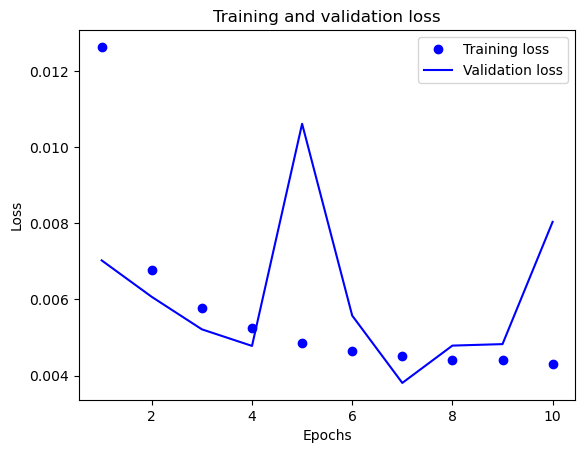

In [9]:
history_dict = history_noise.history
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)
plt.plot(epochs, loss_values, "bo", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

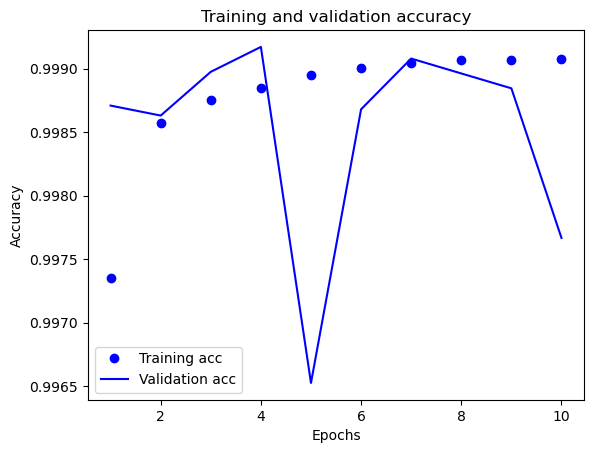

In [10]:
plt.clf()
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]
plt.plot(epochs, acc, "bo", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [11]:
results = model.evaluate(X_test, y_test)

194487/194487 [==============================] - 297s 2ms/step - loss: 1241307021312.0000 - accuracy: 0.9976


In [12]:
pred = model.predict(X_test)
pred

194487/194487 [==============================] - 306s 2ms/step


array([[0.99999994],
       [1.        ],
       [0.99999887],
       ...,
       [1.        ],
       [0.99965006],
       [0.9999999 ]], dtype=float32)

In [13]:
for i in range(len(pred)):
    if pred[i] >= 0.5:
        pred[i] = 1
    else:
        pred[i] = 0

In [14]:
pred

array([[1.],
       [1.],
       [1.],
       ...,
       [1.],
       [1.],
       [1.]], dtype=float32)

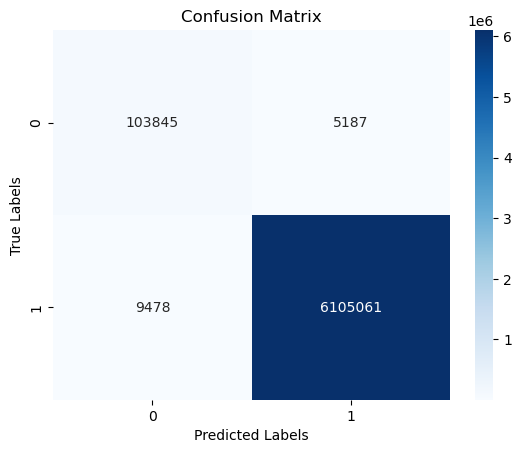

In [15]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

In [16]:
import pickle 

In [17]:
# Save the trained model to a file
with open('DIGITS_ML.pkl', 'wb') as f:
    pickle.dump(model, f)


In [18]:
# Save the StandardScaler object to a file
with open('DIGITS_scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)


In [19]:
pred_val = model.evaluate(val_x, val_y)

71232/71232 [==============================] - 142s 2ms/step - loss: 0.0784 - accuracy: 0.9930


In [20]:
pre_val= model.predict(val_x)
pre_val

71232/71232 [==============================] - 148s 2ms/step


array([[0.998759  ],
       [0.99876064],
       [0.99876237],
       ...,
       [0.9945547 ],
       [0.9945398 ],
       [0.99453217]], dtype=float32)

In [21]:
for i in range(len(pre_val)):
    if pre_val[i] >= 0.5:
        pre_val[i] = 1
    else:
        pre_val[i] = 0

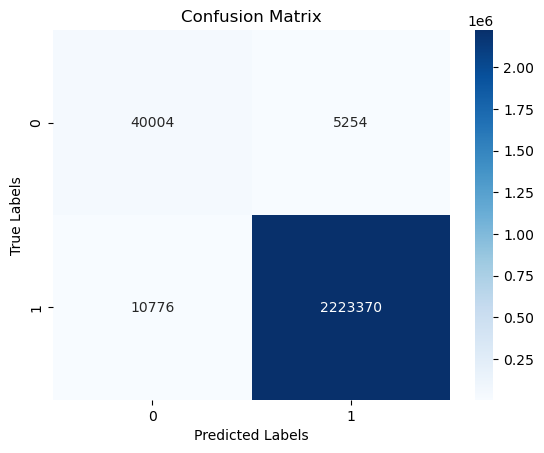

In [22]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
cm = confusion_matrix(val_y, pre_val)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

In [23]:
# Add the predictions to the new dataset
val['PREDICTIONS'] = pre_val

val['TM_STAMP'] = pd.to_datetime(val['TM_STAMP'], unit='s')
val

,Unnamed: 0,ID_PIEZO,TM_STAMP,DIGITS,AMP,REPORTABLE,PREDICTIONS
0,0,1109,2023-01-01 01:00:00,8584.845703,2.8750,True,1.0
1,1,1109,2023-01-01 02:00:00,8584.845703,2.8750,True,1.0
2,2,1109,2023-01-01 03:00:00,8584.852539,2.8750,True,1.0
3,3,1109,2023-01-01 04:00:00,8584.845703,2.8750,True,1.0
4,4,1101,2023-01-01 00:00:00,8789.166016,2.6875,True,1.0
...,...,...,...,...,...,...,...
2428397,2428397,1182,2023-01-11 02:00:00,8937.125977,2.3125,True,1.0
2428400,2428400,1182,2023-01-12 03:00:00,8937.468750,2.3125,True,1.0
2428402,2428402,1182,2023-01-12 14:00:00,8937.841797,2.3125,True,1.0
2428403,2428403,1182,2023-01-12 16:00:00,8937.884766,2.3125,True,1.0


In [24]:
import pandas as pd
from sklearn.metrics import confusion_matrix

# Assuming you already have the new_data dataframe
# Step 2: Create a new column to store the comparison results
val['COMPARE'] = val['REPORTABLE'] == (val['PREDICTIONS'] == 1)

# Get unique ID_PIEZO values for predicted false and actual REPORTABLE false
predicted_false = val.loc[val['PREDICTIONS'] == 0, 'ID_PIEZO'].unique()
actual_reportable_false = val.loc[val['REPORTABLE'] == False, 'ID_PIEZO'].unique()

# Save the unique ID_PIEZO's for predicted false and actual REPORTABLE false in separate text files
with open("ID_PIEZO_Predicted_False.txt", 'w') as f:
    for id_piezo in predicted_false:
        f.write(str(id_piezo) + '\n')

with open("ID_PIEZO_Actual_Reportable_False.txt", 'w') as f:
    for id_piezo in actual_reportable_false:
        f.write(str(id_piezo) + '\n')

# Step 4: Create a confusion matrix
y_true = val['REPORTABLE']
y_pred = val['PREDICTIONS'].apply(lambda x: x == 1)  # Convert 1's and 0's to boolean values
cm = confusion_matrix(y_true, y_pred)

# Create a labeled confusion matrix using a Pandas DataFrame
labeled_cm = pd.DataFrame(cm, index=['Actual: False', 'Actual: True'], columns=['Predicted: False', 'Predicted: True'])

print("Confusion Matrix:")
print(labeled_cm)


Confusion Matrix:
               Predicted: False  Predicted: True
Actual: False             40004             5254
Actual: True              10776          2223370


In [27]:
# Save the new dataset with predictions to a CSV file
val.to_csv('worked.csv', index=False)

PermissionError: [Errno 13] Permission denied: 'worked.csv'